# Phân tích dữ liệu

In [1]:
import os
import numpy as np
from PIL import Image

train_dir = "cifar10/train"
test_dir = "cifar10/test"

# Lấy tên các class từ các thư mục con trong tập train
classes = sorted(os.listdir(train_dir))
print(classes)

labels = {
    class_name: label
    for label, class_name in enumerate(classes)
}
print(labels)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
{'airplane': 0, 'automobile': 1, 'bird': 2, 'cat': 3, 'deer': 4, 'dog': 5, 'frog': 6, 'horse': 7, 'ship': 8, 'truck': 9}


In [5]:
from concurrent.futures import ThreadPoolExecutor

def read_image(args):
    file_path, label = args

    image = Image.open(file_path).convert("RGB")
    image = np.array(image)

    return image, label


def sortXy(dir):
    tasks = []

    for class_name in classes:
        class_dir = os.path.join(dir, class_name)
        label = labels[class_name]

        for file_name in os.listdir(class_dir):
            if file_name.lower().endswith((".png", ".jpg", ".jpeg")):
                file_path = os.path.join(class_dir, file_name)
                tasks.append((file_path, label))

    with ThreadPoolExecutor(max_workers=8) as executor:
        results = list(executor.map(read_image, tasks))

    X, y = zip(*results)

    return np.array(X), np.array(y)

In [6]:
X_train, y_train = sortXy(train_dir)
X_test, y_test = sortXy(test_dir)

print("Classes:", classes)
print("Number of classes:", len(classes))
print("X train shape:", X_train.shape)
print("y train shape:", y_train.shape)
print("X test shape:", X_test.shape)
print("y test shape:", y_test.shape)

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of classes: 10
X train shape: (50000, 32, 32, 3)
y train shape: (50000,)
X test shape: (10000, 32, 32, 3)
y test shape: (10000,)


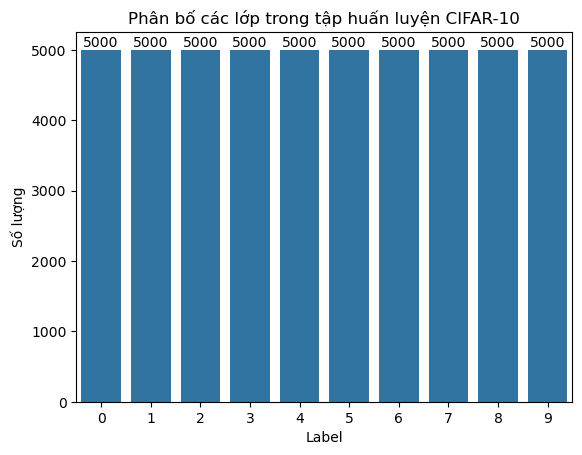

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.countplot(x=y_train)

for container in ax.containers:
    ax.bar_label(container)

plt.xlabel("Label")
plt.ylabel("Số lượng")
plt.title("Phân bố các lớp trong tập huấn luyện CIFAR-10")
plt.show()

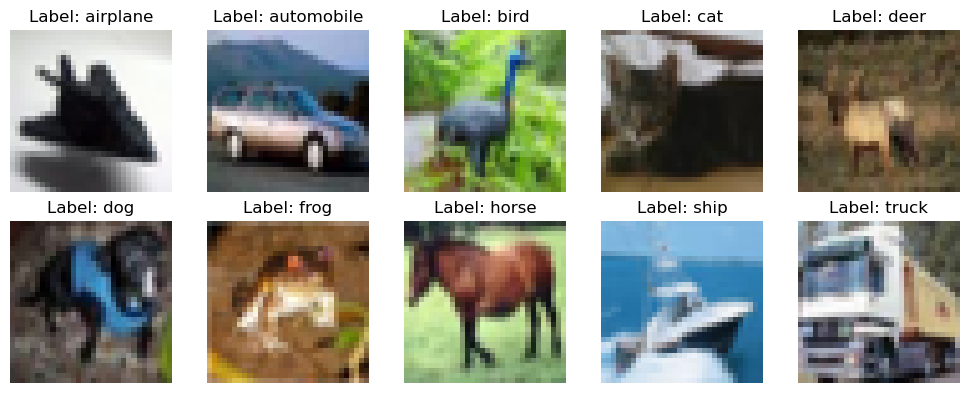

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i, c in enumerate(classes):
    idx = np.where(y_train == i)[0][0]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[idx], cmap="gray")
    plt.title(f"Label: {c}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Chuẩn hóa

In [11]:
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# Huấn luyện

In [12]:
def drawLvsE(losses):
    plt.plot(losses)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training Loss")
    plt.show()

## Nếu cần

In [ ]:
import joblib

joblib.dump(
    [X_train, y_train, X_test, y_test], "cifar_data.pkl"
)

In [ ]:
#X_train, y_train, X_test, y_test = joblib.load("cifar_data.pkl")

## CNN PyTorch

In [41]:
import torch
import torch.nn as nn
import torch.optim as optim

In [42]:
# Chuyển về tensor
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

X_train_t = X_train_t.permute(0, 3, 1, 2)
X_test_t = X_test_t.permute(0, 3, 1, 2)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print(X_train_t.shape, X_test_t.shape)
print(y_train_t.shape, y_test_t.shape)

torch.Size([50000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])
torch.Size([50000]) torch.Size([10000])


In [43]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Conv 1
        self.conv1 = nn.Conv2d(3, 8, 3)

        # Pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Conv 2
        self.conv2 = nn.Conv2d(8, 8, 3)

        # Fully Connected
        self.fc1 = nn.Linear(8 * 6 * 6, 16)

        self.fc2 = nn.Linear(16, len(classes))

    def forward(self, x):

        # Conv 1 → ReLU → Pool
        x = self.conv1(x)
        x = torch.relu(x)
        x = self.pool(x)

        # Conv 2 → ReLU → Pool
        x = self.conv2(x)
        x = torch.relu(x)
        x = self.pool(x)

        # Flatten
        x = x.reshape(x.size(0), -1)

        # Dense
        x = self.fc1(x)
        x = torch.relu(x)

        # Output
        x = self.fc2(x)

        return x

In [44]:
model = CNN()

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=0.01
)

In [45]:
epochs = 10
batch_size = 32

losses = []

for epoch in range(epochs):

    permutation = torch.randperm(
        X_train_t.size(0)
    )

    total_loss = 0
    num_batches = 0

    for i in range(0, X_train_t.size(0), batch_size):

        idx = permutation[i:i + batch_size]

        X_batch = X_train_t[idx]
        y_batch = y_train_t[idx]

        optimizer.zero_grad()

        y_hat = model(X_batch)

        loss = criterion(
            y_hat,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()
        num_batches += 1

    avg_loss = total_loss / num_batches

    losses.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"- Loss: {avg_loss:.4f}"
    )

Epoch 1/10 - Loss: 2.2638
Epoch 2/10 - Loss: 2.0436
Epoch 3/10 - Loss: 1.8913
Epoch 4/10 - Loss: 1.7514
Epoch 5/10 - Loss: 1.6595
Epoch 6/10 - Loss: 1.5997
Epoch 7/10 - Loss: 1.5487
Epoch 8/10 - Loss: 1.4970
Epoch 9/10 - Loss: 1.4579
Epoch 10/10 - Loss: 1.4318


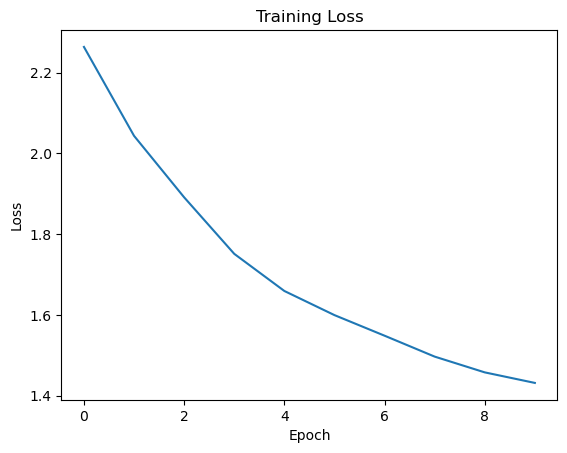

In [46]:
drawLvsE(losses)

## CNN TensorFlow

In [47]:
nf, mf, c = X_train.shape[1:]

In [48]:
import tensorflow as tf

cnn_tf = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(nf, mf, c)),
    tf.keras.layers.Conv2D(
        filters=8,
        kernel_size=3,
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(
        pool_size=2,
        strides=2
    ),
    tf.keras.layers.Conv2D(
        filters=8,
        kernel_size=3,
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(
        pool_size=2,
        strides=2
    ),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(len(classes), activation="softmax")
])

cnn_tf.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 8)      │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,602 (21.88 KB)

 Trainable params: 5,602 (21.88 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
cnn_tf.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [50]:
history_cnn = cnn_tf.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.2037 - loss: 2.1336
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.3484 - loss: 1.8003
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4006 - loss: 1.6713
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4248 - loss: 1.6051
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4432 - loss: 1.5560
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.4581 - loss: 1.5088
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4752 - loss: 1.4638
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4894 - loss: 1.4246
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.5035 - loss: 1.3916
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.5151 - loss: 1.3617


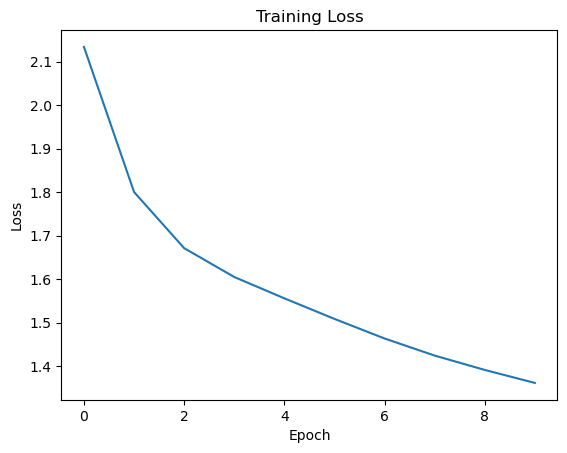

In [57]:
drawLvsE(history_cnn.history["loss"])

# Kết quả

In [52]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

def evaluation(name, y_test, y_prob):
    y_pred = np.argmax(y_prob, axis=1)

    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(
        y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(
        y_test, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    return {
        'Model': name,
        'Accuracy': acc, 'Precision': precision,
        'Recall': recall, 'F1-score': f1,
        'Confusion Matrix': cm
    }

In [53]:
res = []

# CNN PyTorch
with torch.no_grad():
    y_prob = model(X_test_t)
y_prob = y_prob.numpy()
res.append(evaluation("CNN PyTorch", y_test, y_prob))

#CNN TensorFlow
y_prob = cnn_tf.predict(X_test,verbose=0)
res.append(evaluation("CNN TensorFlow", y_test, y_prob))

In [54]:
import pandas as pd

res_df = pd.DataFrame(res).set_index('Model')

metric_df = res_df.drop(columns = ['Confusion Matrix'])

metric_df.sort_values(
    by='Accuracy',
    ascending=False
)

,Accuracy,Precision,Recall,F1-score
Model,,,,
CNN TensorFlow,0.5032,0.515661,0.5032,0.495600
CNN PyTorch,0.4962,0.499053,0.4962,0.485679


In [55]:
for row in res:
    print(row['Model'])
    print(row['Confusion Matrix'])

CNN PyTorch
[[498  65  71  12  10   6  24  10 222  82]
 [ 24 610   3   5   6   2  14   9 111 216]
 [ 72  32 430  56  63  72 136  62  40  37]
 [ 36  30  87 265  27 203 181  52  31  88]
 [ 53  21 213  61 233  42 203 100  37  37]
 [ 14  15 119 155  15 411 108  88  32  43]
 [  4  21  99  53  36  26 680  24  14  43]
 [ 28  22  65  61  41  82  57 520  18 106]
 [ 82  70  16  19   3   4  13   7 694  92]
 [ 32 167  10  22   3  10  22  19  94 621]]
CNN TensorFlow
[[501  33  56  38  33  11  26  60 198  44]
 [ 40 570   7  19  13   8  20  69  72 182]
 [ 64  12 189 112 220  79 106 159  39  20]
 [ 11   8  41 359  87 145 107 200  20  22]
 [ 35   2  61  92 398  41 112 241  12   6]
 [  5   2  45 219  62 342  35 265  15  10]
 [  4   7  20  84  90  25 672  79   8  11]
 [  8   1  13  49  51  56  12 768  14  28]
 [122  35  18  30   8  11  17  44 662  53]
 [ 35  93  11  32   9   7  35 125  82 571]]


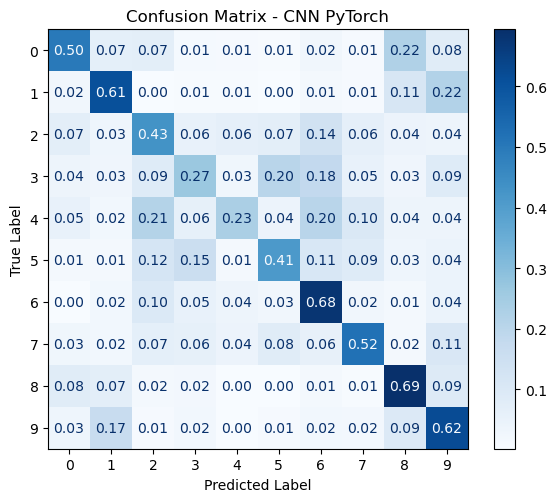

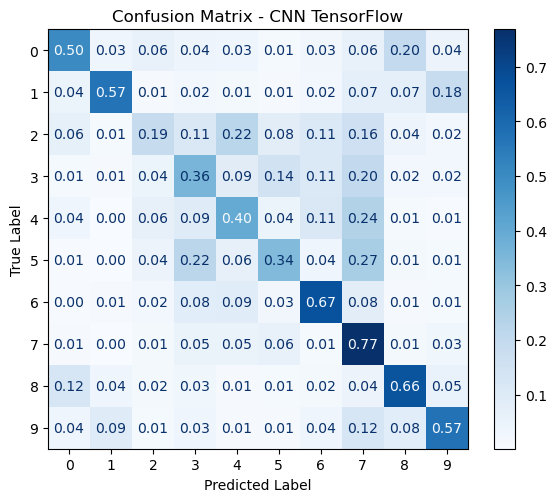

In [56]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for row in res:
    model_name = row['Model']
    cm = row['Confusion Matrix']

    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(6, 5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_norm,
        display_labels=range(10)
    )

    disp.plot(
        ax=ax,
        cmap='Blues',
        values_format='.2f'
    )

    ax.set_title(f'Confusion Matrix - {model_name}')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

    plt.tight_layout()
    plt.show()